## RQ3: Predicting flight delays — choosing the model
This notebook shows why we use an EBM: we compare it with XGBoost on the same features and the same split (train on months 1–6, validate on month 7). The full RQ3 analysis is in `04b_predicting_delays.ipynb`.

### Setup and imports

In [1]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from interpret.glassbox import ExplainableBoostingClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    log_loss,
    brier_score_loss,
    precision_score,
    recall_score,
    f1_score,
)
from xgboost import XGBClassifier

PROJECT_DIR = Path.cwd().resolve()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from src.config import CLEAN_PARQUET, TABLES_DIR
from src.data_loading import load_flights

In [2]:
FLIGHTS_SRC = "flights_2024_clean.parquet"

# Keep each feature group with its source so the modeling inputs are easy to audit.
BASELINE_COLS = [
    ("route_past_delay_rate", "derived from training data separately for each split"),
]
FLIGHT_COLS = [  # standard features from the original flight dataframe
    ("month", FLIGHTS_SRC),
    ("day_of_week", FLIGHTS_SRC),
    ("sched_hour", f"{FLIGHTS_SRC}: crs_dep_time // 100"),
    ("op_unique_carrier", FLIGHTS_SRC),
    ("distance", FLIGHTS_SRC),
]
RQ1_COLS = [
    ("route_cluster", "rq1_route_clusters_jan_jun.csv (joined on origin, dest, op_unique_carrier)"),
    ("cluster_past_delay_rate", "rq1_cluster_delay_rates_jan_jun.csv: historical_delay_rate (joined on route_cluster)"),
]
RQ2_COLS = [
    ("origin_community", "03_airports.csv: louvain (joined on origin)"),
    ("dest_community", "03_airports.csv: louvain (joined on dest)"),
    ("crosses_community", "derived: origin_community != dest_community"),
    ("origin_betweenness", "03_airports.csv: betweenness (joined on origin)"),
    ("dest_betweenness", "03_airports.csv: betweenness (joined on dest)"),
]
OTHER_COLS = [  # not features: route key for the baseline, and the target
    ("origin", FLIGHTS_SRC),
    ("dest", FLIGHTS_SRC),
    ("late_arrival", f"target, {FLIGHTS_SRC}: arr_delay >= 15"),
]

ROUTE_KEYS = ["origin", "dest", "op_unique_carrier"]

BASELINE_FEATURES = [column for column, _ in BASELINE_COLS]
FLIGHT_FEATURES = [column for column, _ in FLIGHT_COLS]
RQ1_FEATURES = [column for column, _ in RQ1_COLS]
RQ2_FEATURES = [column for column, _ in RQ2_COLS]


In [3]:
# Delay columns are loaded only to build the target, never as features.
flights = load_flights(
    CLEAN_PARQUET,
    columns=["month", "day_of_week", "op_unique_carrier", "origin", "dest",
             "crs_dep_time", "distance", "status", "arr_delay"],
)

# Cancelled and diverted flights have no arrival delay.
flights = flights[flights["status"] == "completed"].dropna(subset=["arr_delay"]).reset_index(drop=True)

# Late = arrives 15+ minutes late (official FAA definition).
flights["late_arrival"] = (flights["arr_delay"] >= 15).astype(int)
flights["sched_hour"] = ((flights["crs_dep_time"] // 100) % 24).astype(int)
flights = flights.drop(columns=["status", "arr_delay", "crs_dep_time"])

# RQ1 output: route + airline -> cluster, and the cluster's past delay rate.
route_lookup = pd.read_csv(TABLES_DIR / "rq1_route_clusters_jan_jun.csv")
route_rates = pd.read_csv(TABLES_DIR / "rq1_cluster_delay_rates_jan_jun.csv")[
    ["route_cluster", "historical_delay_rate"]
].rename(columns={"historical_delay_rate": "cluster_past_delay_rate"})

flights = flights.merge(route_lookup, on=ROUTE_KEYS, how="left", validate="many_to_one")
flights = flights.merge(route_rates, on="route_cluster", how="left", validate="many_to_one")

# Routes not seen in Jan-Jun have no cluster.
flights["route_cluster"] = flights["route_cluster"].astype("Int64").astype("string").fillna("unknown")

# RQ2 output: community and betweenness of the origin and of the destination airport.
airports = pd.read_csv(TABLES_DIR / "03_airports.csv")[["airport", "louvain", "betweenness"]]
for side in ["origin", "dest"]:
    side_features = airports.rename(columns={
        "airport": side,
        "louvain": f"{side}_community",
        "betweenness": f"{side}_betweenness",
    })
    flights = flights.merge(side_features, on=side, how="left", validate="many_to_one")
    flights[f"{side}_community"] = flights[f"{side}_community"].astype("Int64").astype("string").fillna("unknown")

flights["crosses_community"] = (flights["origin_community"] != flights["dest_community"]).astype(int)

rq3_df = flights[["origin", "dest"] + FLIGHT_FEATURES + RQ1_FEATURES + RQ2_FEATURES + ["late_arrival"]].copy()

print(f"RQ3 modeling dataframe rows: {len(rq3_df):,}")
print(f"Target rate: {rq3_df['late_arrival'].mean():.3%}")
print(f"Unknown route cluster: {(rq3_df['route_cluster'] == 'unknown').mean():.2%}")
print(f"Unknown origin / dest community: {(rq3_df['origin_community'] == 'unknown').mean():.2%} / {(rq3_df['dest_community'] == 'unknown').mean():.2%}")


feature_groups = [
    ("Baseline", BASELINE_COLS),
    ("standard_flight", FLIGHT_COLS),
    ("RQ1", RQ1_COLS),
    ("RQ2", RQ2_COLS),
    ("Other (not features)", OTHER_COLS),
]
for name, cols in feature_groups:
    print(f"{name}")
    for col, src in cols:
        print(f"    {col:<24} <- {src}")

# Dataset columns are accounted for; route keys and the target are not model features.
listed = [c for c, _ in FLIGHT_COLS + RQ1_COLS + RQ2_COLS + OTHER_COLS]
assert sorted(listed) == sorted(rq3_df.columns)


# Only send first 100 rows for inspection
rq3_df.head(100).to_csv(TABLES_DIR / "rq3_modeling_dataframe_head.csv", index=False, header=True)


RQ3 modeling dataframe rows: 6,965,246
Target rate: 20.817%
Unknown route cluster: 1.83%
Unknown origin / dest community: 0.00% / 0.00%
Baseline
    route_past_delay_rate    <- derived from training data separately for each split
standard_flight
    month                    <- flights_2024_clean.parquet
    day_of_week              <- flights_2024_clean.parquet
    sched_hour               <- flights_2024_clean.parquet: crs_dep_time // 100
    op_unique_carrier        <- flights_2024_clean.parquet
    distance                 <- flights_2024_clean.parquet
RQ1
    route_cluster            <- rq1_route_clusters_jan_jun.csv (joined on origin, dest, op_unique_carrier)
    cluster_past_delay_rate  <- rq1_cluster_delay_rates_jan_jun.csv: historical_delay_rate (joined on route_cluster)
RQ2
    origin_community         <- 03_airports.csv: louvain (joined on origin)
    dest_community           <- 03_airports.csv: louvain (joined on dest)
    crosses_community        <- derived: origin_communit

In [4]:
# How much data we have: overall, per month, and per rolling window (train months 1..m-1, test month m).
n_total = len(rq3_df)
print(f"Rows: {n_total:,} | columns: {rq3_df.shape[1]} | memory: {rq3_df.memory_usage(deep=True).sum() / 1e6:,.0f} MB")
print(f"Late flights: {rq3_df['late_arrival'].sum():,} ({rq3_df['late_arrival'].mean():.2%})")
print(f"Distinct airports: {pd.concat([rq3_df['origin'], rq3_df['dest']]).nunique()} | "
      f"airlines: {rq3_df['op_unique_carrier'].nunique()} | "
      f"route+airline pairs: {rq3_df.groupby(['origin', 'dest', 'op_unique_carrier'], observed=True).ngroups:,}")

per_month = rq3_df.groupby("month")["late_arrival"].agg(flights="size", late="sum", late_rate="mean")
per_month["late_rate"] = (per_month["late_rate"] * 100).round(2)
print("\nFlights per month")
print(per_month.to_string())

windows = pd.DataFrame([
    {
        "window": test_month - 6,
        "train_months": f"1-{test_month - 1}",
        "test_month": test_month,
        "train_flights": int(per_month.loc[:test_month - 1, "flights"].sum()),
        "test_flights": int(per_month.loc[test_month, "flights"]),
        "train_late_rate": round(per_month.loc[:test_month - 1, "late"].sum() / per_month.loc[:test_month - 1, "flights"].sum() * 100, 2),
        "test_late_rate": per_month.loc[test_month, "late_rate"],
    }
    for test_month in range(7, 13)
])
print("\nRolling evaluation windows")
print(windows.to_string(index=False))


Rows: 6,965,246 | columns: 15 | memory: 788 MB
Late flights: 1,449,962 (20.82%)
Distinct airports: 348 | airlines: 15 | route+airline pairs: 13,238

Flights per month
       flights    late  late_rate
month                            
1       525370  126410      24.06
2       515265   82033      15.92
3       585411  122031      20.85
4       576933  109953      19.06
5       599223  158275      26.41
6       601270  149944      24.94
7       613938  181865      29.62
8       604299  141810      23.47
9       578262   89678      15.51
10      608513   80343      13.20
11      571931   83899      14.67
12      584831  123721      21.16

Rolling evaluation windows
 window train_months  test_month  train_flights  test_flights  train_late_rate  test_late_rate
      1          1-6           7        3403472        613938            22.00           29.62
      2          1-7           8        4017410        604299            23.16           23.47
      3          1-8           9        4621

### Feature groups

In [5]:
for name, features in [
    ("Baseline", BASELINE_FEATURES),
    ("standard_flight", FLIGHT_FEATURES),
    ("RQ1", RQ1_FEATURES),
    ("RQ2", RQ2_FEATURES),
]:
    print(f"{name}: {features}")

Baseline: ['route_past_delay_rate']
standard_flight: ['month', 'day_of_week', 'sched_hour', 'op_unique_carrier', 'distance']
RQ1: ['route_cluster', 'cluster_past_delay_rate']
RQ2: ['origin_community', 'dest_community', 'crosses_community', 'origin_betweenness', 'dest_betweenness']


### Validation split, per-route baseline, and model comparison
Train on months 1–6, validate on July. The route delay rate is computed exactly as in notebook 04b: a training flight in month m only uses the months before m (January has no history and gets the prior 0.5), and July uses all of months 1–6. No flight ever sees its own outcome, so there is no target leakage in the training rows either.

In [6]:
# Split data
train = rq3_df[rq3_df["month"].between(1, 6)].copy()
val = rq3_df[rq3_df["month"] == 7].copy()

train["op_unique_carrier"] = train["op_unique_carrier"].astype("category")
val["op_unique_carrier"] = val["op_unique_carrier"].astype("category")

In [7]:
# Leakage-safe route delay rate, the same functions as in notebook 04b:
# a row in month m only uses the training months before m; the validation month uses all training months.
def historical_rate_table(train, keys, val_month, smoothing=20, initial_prior=0.5):
    """Smoothed late rate per key for every training month and for the validation month."""
    monthly = train.groupby(keys + ["month"], observed=True)["late_arrival"].agg(["sum", "count"]).reset_index()
    month_totals = train.groupby("month", observed=True)["late_arrival"].agg(["sum", "count"])
    tables, priors = [], {}
    for month in sorted(train["month"].unique()) + [val_month]:
        history_months = month_totals.index[month_totals.index < month]
        totals = month_totals.loc[history_months].sum()
        prior = totals["sum"] / totals["count"] if totals["count"] > 0 else float(initial_prior)
        stats = (monthly[monthly["month"].isin(history_months)]
                 .groupby(keys, observed=True)[["sum", "count"]].sum().reset_index())
        stats["rate"] = (stats["sum"] + smoothing * prior) / (stats["count"] + smoothing)
        stats["month"] = month
        tables.append(stats[keys + ["month", "rate"]])
        priors[month] = prior
    return pd.concat(tables, ignore_index=True), priors


def add_rate(rows, rate_table, priors, keys, months):
    """Join the rate of each row's key and month; keys without history get that month's prior."""
    lookup = rows[keys].copy()
    lookup["month"] = months
    merged = lookup.merge(rate_table, on=keys + ["month"], how="left", validate="many_to_one", sort=False)
    return pd.Series(merged["rate"].fillna(merged["month"].map(priors)).to_numpy(), index=rows.index)


rate_table, priors = historical_rate_table(train, ROUTE_KEYS, val_month=7)
train["route_past_delay_rate"] = add_rate(train, rate_table, priors, ROUTE_KEYS, train["month"].to_numpy())
val["route_past_delay_rate"] = add_rate(val, rate_table, priors, ROUTE_KEYS, 7)

In [8]:
# Sample training data
train = train.sample(n=200_000, random_state=42)

results = {}

for name, features in [
    ("Baseline", BASELINE_FEATURES),
    ("standard_flight", FLIGHT_FEATURES),
]:
    # 4 outer bags, so 4 parallel jobs are enough; more jobs only add processes and memory (same setting as 04b)
    model = ExplainableBoostingClassifier(random_state=42, interactions=0, outer_bags=4, n_jobs=4)
    model.fit(train[features], train["late_arrival"])

    probs = model.predict_proba(val[features])[:, 1]
    preds = (probs >= 0.5).astype(int)
    y = val["late_arrival"]

    results[name] = {
        "ROC-AUC": roc_auc_score(y, probs),
        "PR-AUC": average_precision_score(y, probs),
        "Log Loss": log_loss(y, probs),
        "Brier Score": brier_score_loss(y, probs),
        "Precision": precision_score(y, preds, zero_division=0),
        "Recall": recall_score(y, preds, zero_division=0),
        "F1": f1_score(y, preds, zero_division=0),
    }

# Compare models
results_df_ebm = pd.DataFrame(results).T
display(results_df_ebm.round(4))

,ROC-AUC,PR-AUC,Log Loss,Brier Score,Precision,Recall,F1
Baseline,0.5871,0.3614,0.6126,0.2100,0.4393,0.0056,0.0110
standard_flight,0.6685,0.4338,0.5790,0.1971,0.5000,0.0002,0.0004


In [9]:
results = {}

for name, features in [
    ("Baseline", BASELINE_FEATURES),
    ("standard_flight", FLIGHT_FEATURES),
]:
    model = XGBClassifier(
        n_estimators=100,
        max_depth=6,
        enable_categorical=True,
        tree_method="hist",
        random_state=42
    )
    model.fit(train[features], train["late_arrival"])

    probs = model.predict_proba(val[features])[:, 1]
    preds = (probs >= 0.5).astype(int)
    y = val["late_arrival"]

    results[name] = {
        "ROC-AUC": roc_auc_score(y, probs),
        "PR-AUC": average_precision_score(y, probs),
        "Log Loss": log_loss(y, probs),
        "Brier Score": brier_score_loss(y, probs),
        "Precision": precision_score(y, preds, zero_division=0),
        "Recall": recall_score(y, preds, zero_division=0),
        "F1": f1_score(y, preds, zero_division=0),
    }

# Compare models
results_df_xgb = pd.DataFrame(results).T
display(results_df_xgb.round(4))

,ROC-AUC,PR-AUC,Log Loss,Brier Score,Precision,Recall,F1
Baseline,0.5836,0.3580,0.6132,0.2101,0.4624,0.0039,0.0076
standard_flight,0.6683,0.4365,0.5804,0.1963,0.5321,0.0734,0.1290


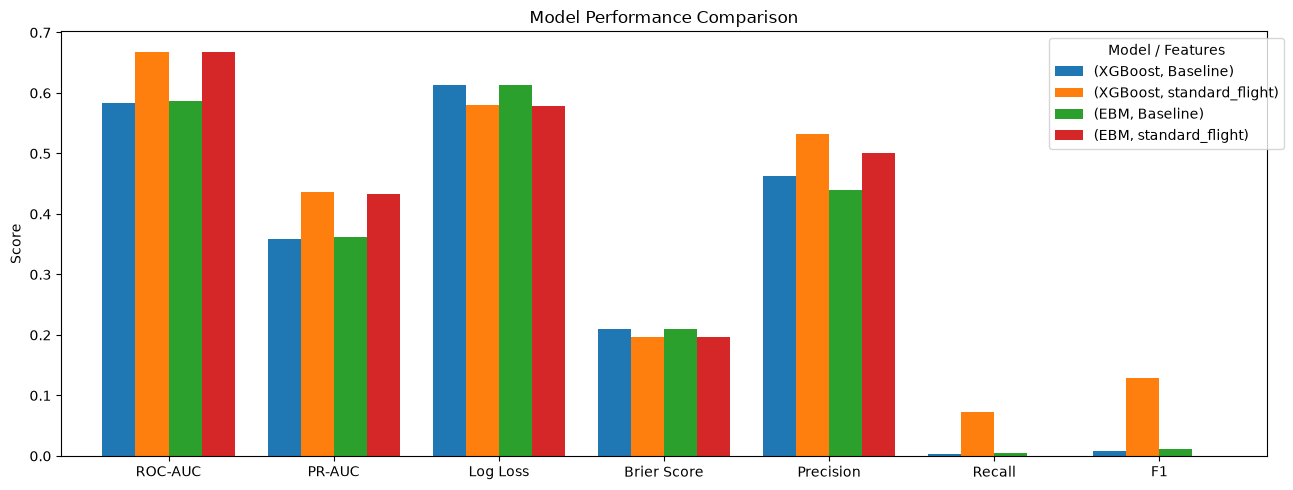

In [10]:
# Combine results
results_combined = pd.concat({
    "XGBoost": results_df_xgb,
    "EBM": results_df_ebm
})

# Plot metrics
ax = results_combined.T.plot(
    kind="bar",
    figsize=(13, 5),
    rot=0,
    width=0.8
)

ax.set_title("Model Performance Comparison")
ax.set_ylabel("Score")
ax.legend(title="Model / Features", bbox_to_anchor=(1.02, 1))
plt.tight_layout()

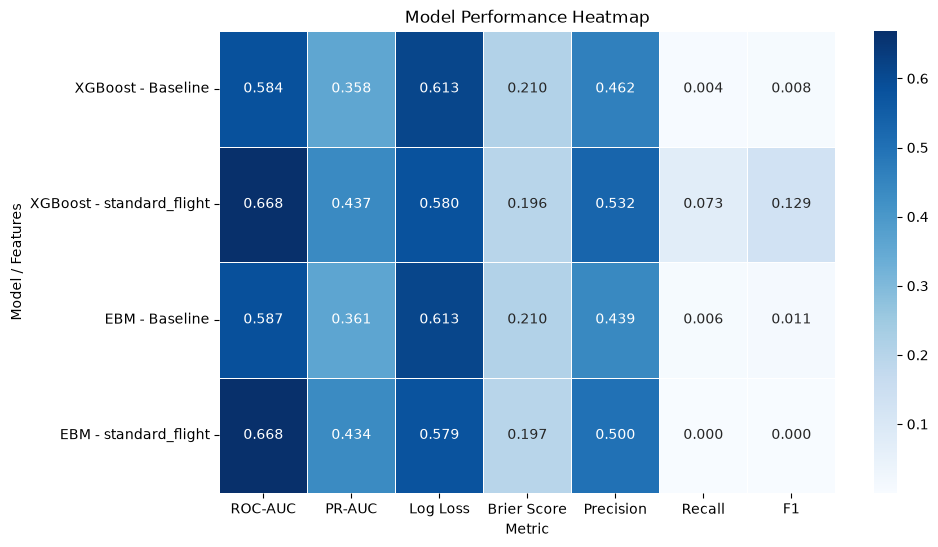

In [11]:
plt.figure(figsize=(14, 6))

ax = sns.heatmap(
    results_combined,
    annot=True,
    fmt=".3f",
    cmap="Blues",
    linewidths=0.5
)

ax.set_yticklabels(
    [f"{model} - {features}" for model, features in results_combined.index],
    rotation=0
)

plt.title("Model Performance Heatmap")
plt.xlabel("Metric")
plt.ylabel("Model / Features")

plt.yticks(rotation=0)
plt.subplots_adjust(left=0.35)

plt.show()

**Takeaway:** On the same features and split (train months 1–6, validate on July), the EBM and XGBoost perform the same: ROC-AUC 0.669 vs 0.668 and PR-AUC 0.434 vs 0.437, both clearly above the route baseline (0.587 ROC-AUC). Since XGBoost is not better, we use the EBM: it is a glass-box model whose effect of every feature can be plotted and checked (see the shape functions in notebook 04b), which matters more for our question than a black-box score.

At the default threshold of 0.5 both models predict almost no flight as late (EBM recall 0.0002), because only about 30% of July flights are late and the predicted probabilities rarely reach 0.5. Precision, recall and F1 at 0.5 are therefore not meaningful here; notebook 04b compares models with ROC-AUC and PR-AUC and chooses the probability threshold on the validation months.